# T12 · demo local de actividad y salidas GRU

Carga pesos del proyecto, dibuja una frase y predice fonemas en la celda
siguiente. Usa el kernel **.venv local con CUDA** y dos hilos CPU.

- La configuración está en `configs/speech_demo_salidas.yaml`.
- Por defecto carga la conjunta real de **200 pasos**, run **xz71t4vd**,
  con las salidas entrenadas **2/3/5**.
- Usa la primera frase de **validación** de la sesión configurada; no escoge
  el ejemplo según el resultado. Es una demo del pipeline, no un modelo convergido.
- `split: auto` usa val con el protocolo nuevo y test con pesos históricos.

Instalación desde el terminal del proyecto: `python -m pip install -r requirements-demo.txt`.
La demo usa datos preparados compatibles con los pesos y guarda sus salidas
en `runs/demo_salidas/`. No instala paquetes ni descarga datos desde las celdas.


In [1]:
from pathlib import Path
import os
import sys
import yaml

PROJECT = next((path for path in (Path.cwd(), *Path.cwd().parents)
                if (path / "run.py").is_file() and (path / "src/models/speech_gru.py").is_file()), None)
if PROJECT is None:
    raise RuntimeError("Abre este notebook desde el repositorio del proyecto.")
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
CONFIG = Path("configs/speech_demo_salidas.yaml")
cfg = yaml.safe_load(CONFIG.read_text(encoding="utf-8"))
for name in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[name] = str(cfg["ejecucion"]["hilos_cpu"])

from IPython.display import Image, display
from scripts.demo_speech_profiles import load_demo, create_controls
print("Python:", sys.executable)
print("Configuración:", CONFIG)


Python: /run/media/hjasi/neural_data/Trabajo Integrado/tic_proyecto/.venv/bin/python
Configuración: configs/speech_demo_salidas.yaml


## Cargar el checkpoint y la frase fija

La arquitectura, vocabulario y normalización salen de los pesos. La carga
comprueba su compatibilidad con las señales y etiquetas preparadas.
`frase` es una posición dentro de la sesión y split elegidos; se muestra
también el índice del ensayo en el archivo original. La selección está
fijada en el YAML y no depende del error de la predicción.


In [2]:
if "demo" in globals():
    demo.close()
demo = load_demo(cfg)
print("Checkpoint:", demo.metadata["checkpoint"])
print("Paso guardado:", demo.metadata["checkpoint_step"])
print("Salidas disponibles:", demo.available_exits)
print("Dispositivo:", demo.metadata["hardware"])
print("Split:", demo.metadata["split"], "· sesión:", demo.metadata["session"],
      "· ensayo original:", demo.metadata["source_trial_index"])
print("Referencia:", demo.metadata["reference_text"])
print("Salidas de esta demo:", demo.output)


Checkpoint: checkpoints/speech_salidas_e1/xz71t4vd/mejor_val.pt
Paso guardado: 200
Salidas disponibles: (2, 3, 5)
Dispositivo: NVIDIA GeForce RTX 2060
Split: val · sesión: t12.2022.04.28 · ensayo original: 220
Referencia: The giant redwoods shimmered in the glistening sun.
Salidas de esta demo: runs/demo_salidas/5275edd8dadf_ff51dcd7


## Actividad neuronal de la frase

Las dos imágenes muestran tx1 y spikePow de 6v, normalizados con train y
suavizados: la entrada que reciben todas las salidas. Los límites de color
son de visualización; se conservan los valores de la entrada del modelo.


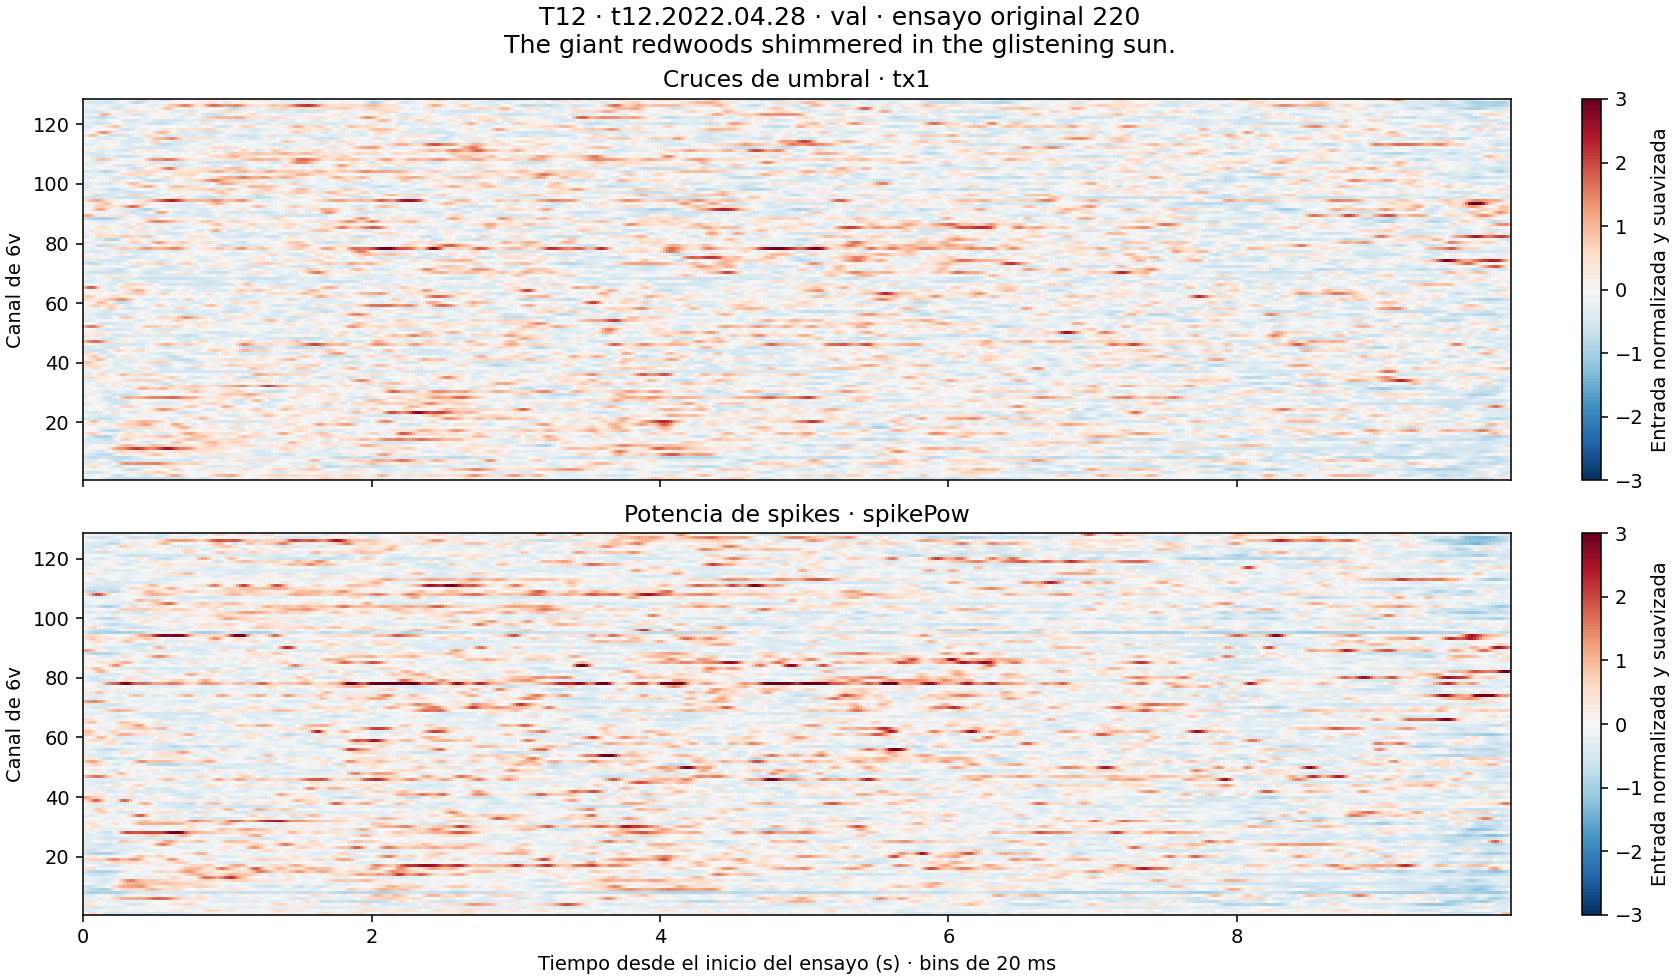

Entrada: [495, 256] · duración: 9.90 s


In [3]:
activity = demo.draw_activity()
display(Image(filename=str(activity)))
print("Entrada:", demo.metadata["input_shape"], "· duración:", f"{demo.metadata['duration_seconds']:.2f} s")


## Predecir fonemas con el perfil elegido

Selecciona **2, 3 o 5 capas** y pulsa **Predecir fonemas**. Se muestra
el prefijo de GRU ejecutado, los fonemas y PER de esta frase, incluyendo SIL.
La mediana de tiempo corresponde solo a la red con entrada ya preparada,
tras el calentamiento definido en el YAML. La comparación de todo el corpus
y la medición desde señal cruda se hacen con los evaluadores del proyecto.

El selector se construye desde los pesos cargados. La conjunta xz71t4vd
ofrece 2/3/5. Si se carga la referencia histórica de 2.001 pasos, ofrece solo 5.


In [4]:
controls = create_controls(demo)
display(controls)


También se puede predecir desde Python con `demo.predict(capa)` o por terminal
con `python scripts/demo_speech_profiles.py --exit-layer CAPA`. El perfil debe
existir en los pesos. Para liberar la GPU al terminar, ejecuta `demo.close()`.
La demo conserva configuración y procedencia y guarda un JSON por perfil;
no abre un run W&B ni actualiza pesos.
